# Answer correctness (`LLM as a judge` method)

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import sys
sys.path.append("..")

import pandas as pd
from pathlib import Path

from evaluation import results, dataset, rag_metrics as ragm
from backend import retriever


SPLIT_PATH = Path("../data/eval/split.json")
dev, test = dataset.load_split(SPLIT_PATH)
print(f"{len(dev)} dev questions available")
print(f"{len(test)} test questions available")

d:\Aanaconda\envs\ukask\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


20 dev questions available
80 test questions available


## Dev Set Results

### `Baseline` system with `Dense` retrieval and `k=5`

In [5]:
rows = ragm.evaluate_answers(dev, k=5)

d:\Aanaconda\envs\ukask\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


    loading embedding model, ~2GB, first run downloads it, be patient...


Loading weights: 100%|██████████| 391/391 [00:00<00:00, 18481.69it/s]


    embedding model ready


In [6]:
df = pd.DataFrame(rows)
df[["id", "question", "ground_truth", "generated_answer", "reasoning",]]

,id,question,ground_truth,generated_answer,reasoning
0,21,حداکثر مرخصی تحصیلی در کارشناسی پیوسته چند نیم...,دو نیمسال,بر اساس تبصره 5 ماده ۷ آیین‌نامه آموزشی (صفحه ...,پاسخ سیستم به‌درستی حداکثر مرخصی تحصیلی در کار...
1,26,آیا انتقال از دانشگاه غیردولتی به دولتی مجاز است؟,خیر,بر اساس ماده ۱۳ آیین‌نامه (سند ۱، صفحه ۳) و ما...,پاسخ سیستم به طور دقیق ممنوعیت انتقال را بیان ...
2,13,حداقل تعداد واحد قابل اخذ در هر نیمسال کارشناس...,۱۲ واحد,طبق ماده ۱۷ آیین‌نامه‌های ارائه‌شده (صفحات ۶ و...,پاسخ سیستم به‌طور دقیق حداقل تعداد واحد قابل ا...
3,64,میانگین کل قابل قبول پس از گذراندن واحدهای آمو...,۱۶,میانگین کل قابل قبول پس از گذراندن تمام واحدها...,پاسخ سیستم به درستی بیان می‌کند که میانگین کل ...
4,81,حداقل نمره قبولی رساله دکتری چقدر است؟,۱۶,حداقل نمره قبولی در ارزشیابی کیفی رساله دکتری،...,پاسخ سیستم به درستی حداقل نمره قبولی رساله دکت...
5,48,آیا تسهیلات حذف نمره مردودی شامل موارد تقلب می...,خیر,خیر، تسهیلات مندرج در ماده ۱۰ (به‌ویژه تبصره ۲...,پاسخ سیستم نکته اصلی را دقیقاً بیان کرده و توض...
6,69,آیا تغییر رشته یا انتقال در دکتری تخصصی مجاز است؟,خیر,خیر، تغییر رشته یا انتقال دانشجوی دوره دکتری ت...,پاسخ سیستم با بیان نکته اصلی که تغییر رشته یا ...
7,3,چند نیمسال مشروطی در کارشناسی ارشد موجب محرومی...,دو نیمسال مشروطی اعم از متوالی یا متناوب,بر اساس ماده ۲۹ سند ۱ و ماده ۲۳ سند ۵، در دوره...,پاسخ سیستم نکته اصلی پاسخ صحیح را بیان کرده و ...
8,45,عدم انتخاب واحد در یک نیمسال چه حکمی دارد؟,به عنوان انصراف از تحصیل تلقی می‌شود,عدم مراجعه دانشجو برای ثبت‌نام و انتخاب واحد د...,پاسخ سیستم مفهوم اصلی پاسخ صحیح را به درستی بی...
9,92,شیوه‌نامه اجرایی هر ورودی تا چه زمانی ملاک عمل...,تا پایان دوره تحصیلی همان ورودی,بر اساس تبصره ۶ ماده ۵۱ سند ۱، برای دانشجویان ...,پاسخ سیستم نکته اصلی پاسخ صحیح را بیان کرده و ...


#### Cross-tab

Rows: whether the labeled article got retrieved. Columns: what the judge
said about the answer. Top-right (miss, but correct) and bottom-left (hit,
but wrong) are the interesting cells, retrieval and generation failing independently.

In [7]:
pd.crosstab(df["article_hit"], df["verdict"])

verdict,correct
article_hit,
False,7
True,13


#### Disagreements

Especially the miss-but-correct cases

In [8]:
disagreements = df[
    ((df["article_hit"] == False) & (df["verdict"] == "correct")) |
    ((df["article_hit"] == True) & (df["verdict"] == "incorrect"))
]

for _, r in disagreements.iterrows():
    print(f"Q{r['id']}  article_hit={r['article_hit']}  verdict={r['verdict']}")
    print(f"  Q: {r['question']}")
    print(f"  ground truth: {r['ground_truth']}")
    print(f"  generated:    {r['generated_answer']}")
    print(f"  judge said:   {r['reasoning']}")
    print()

Q21  article_hit=False  verdict=correct
  Q: حداکثر مرخصی تحصیلی در کارشناسی پیوسته چند نیمسال است؟
  ground truth: دو نیمسال
  generated:    بر اساس تبصره 5 ماده ۷ آیین‌نامه آموزشی (صفحه ۲۴)، حداکثر مرخصی و حذف ترم مجاز برای دانشجویان دوره‌های کارشناسی پیوسته دو نیمسال می‌باشد.
  judge said:   پاسخ سیستم به‌درستی حداکثر مرخصی تحصیلی در کارشناسی پیوسته را دو نیمسال بیان کرده است.

Q48  article_hit=False  verdict=correct
  Q: آیا تسهیلات حذف نمره مردودی شامل موارد تقلب می‌شود؟
  ground truth: خیر
  generated:    خیر، تسهیلات مندرج در ماده ۱۰ (به‌ویژه تبصره ۲ آن) شامل دانشجویانی نمی‌شود که به دلیل تقلب یا حکم انضباطی نمره مردودی دریافت کرده‌اند ([سند ۱ | صفحه ۴ ماده ۲۰]، [سند ۲ | صفحه ۴ ماده ۱۰]).
  judge said:   پاسخ سیستم نکته اصلی را دقیقاً بیان کرده و توضیحات اضافی مرتبط و بدون تناقض است.

Q45  article_hit=False  verdict=correct
  Q: عدم انتخاب واحد در یک نیمسال چه حکمی دارد؟
  ground truth: به عنوان انصراف از تحصیل تلقی می‌شود
  generated:    عدم مراجعه دانشجو برای ثبت‌نام و انتخاب 

#### Saving the results

In [ ]:
results.save_results(
    rows,
    "../data/eval/results/answers_baseline.json",
    label="v2_dense_answers",
)

### `Hybrid` Retrieval

In [ ]:
hybrid_rows = ragm.evaluate_answers(dev, k=5, search_fn=retriever.search_hybrid)
hybrid_df = pd.DataFrame(hybrid_rows)
pd.crosstab(hybrid_df["article_hit"], hybrid_df["verdict"])

verdict,correct
article_hit,
False,8
True,12


In [ ]:
results.save_results(
    hybrid_rows,
    "../data/eval/results/answers_hybrid.json",
    label="v2_hybrid_answers",
)

## Test Set Results

In [3]:
dense_test_rows = ragm.evaluate_answers(
    test, k=5,
    save_path="../data/eval/results/answers_dense_test.json",
)

    loading embedding model, ~2GB, first run downloads it, be patient...


Loading weights: 100%|██████████| 391/391 [00:00<00:00, 24708.43it/s]


    embedding model ready
    1/80 done (id=60, verdict=correct)
    2/80 done (id=51, verdict=correct)
    3/80 done (id=63, verdict=correct)
    4/80 done (id=76, verdict=correct)
    5/80 done (id=22, verdict=correct)
    6/80 done (id=25, verdict=correct)
    7/80 done (id=65, verdict=correct)
    8/80 done (id=18, verdict=correct)
    9/80 done (id=49, verdict=correct)
    10/80 done (id=34, verdict=correct)
    11/80 done (id=94, verdict=correct)
    12/80 done (id=14, verdict=correct)
    13/80 done (id=58, verdict=correct)
    14/80 done (id=1, verdict=incorrect)
    15/80 done (id=93, verdict=partial)
    16/80 done (id=27, verdict=incorrect)
    17/80 done (id=43, verdict=correct)
    18/80 done (id=6, verdict=correct)
    19/80 done (id=87, verdict=correct)
    20/80 done (id=66, verdict=correct)
    21/80 done (id=50, verdict=correct)
    22/80 done (id=10, verdict=correct)
    23/80 done (id=57, verdict=correct)
    24/80 done (id=11, verdict=correct)
    25/80 done (id=28

In [4]:
dense_test_df = pd.DataFrame(dense_test_rows)
pd.crosstab(dense_test_df["article_hit"], dense_test_df["verdict"])

verdict,correct,incorrect,partial
article_hit,,,
False,39,3,4
True,27,5,2


In [12]:
pd.crosstab(dense_test_df["difficulty"], dense_test_df["verdict"])

verdict,correct,incorrect,partial
difficulty,,,
easy,24,3,2
hard,15,1,1
medium,27,4,3


In [5]:
results.save_results(
    dense_test_rows,
    "../data/eval/results/final_answers_dense_test.json",
    label="final_answers_dense_test",
)

In [6]:
hybrid_rows_test = ragm.evaluate_answers(test, k=5, search_fn=retriever.search_hybrid, save_path="../data/eval/results/answers_hybrid_test.json",)

    1/80 done (id=60, verdict=correct)
    2/80 done (id=51, verdict=correct)
    3/80 done (id=63, verdict=correct)
    4/80 done (id=76, verdict=correct)
    5/80 done (id=22, verdict=correct)
    6/80 done (id=25, verdict=correct)
    7/80 done (id=65, verdict=correct)
    8/80 done (id=18, verdict=correct)
    9/80 done (id=49, verdict=correct)
    10/80 done (id=34, verdict=correct)
    11/80 done (id=94, verdict=partial)
    12/80 done (id=14, verdict=correct)
    13/80 done (id=58, verdict=correct)
    14/80 done (id=1, verdict=correct)
    15/80 done (id=93, verdict=partial)
    16/80 done (id=27, verdict=correct)
    17/80 done (id=43, verdict=correct)
    18/80 done (id=6, verdict=correct)
    19/80 done (id=87, verdict=correct)
    20/80 done (id=66, verdict=correct)
    21/80 done (id=50, verdict=correct)
    22/80 done (id=10, verdict=correct)
    23/80 done (id=57, verdict=correct)
    24/80 done (id=11, verdict=partial)
    25/80 done (id=28, verdict=correct)
    26/80 d

In [7]:
hybrid_test_df = pd.DataFrame(hybrid_rows_test)
pd.crosstab(hybrid_test_df["article_hit"], hybrid_test_df["verdict"])

verdict,correct,incorrect,partial
article_hit,,,
False,34,1,4
True,36,2,3


In [11]:
pd.crosstab(hybrid_test_df["difficulty"], hybrid_test_df["verdict"])

verdict,correct,incorrect,partial
difficulty,,,
easy,25,0,4
hard,17,0,0
medium,28,3,3


In [8]:
results.save_results(
    hybrid_rows_test,
    "../data/eval/results/final_answers_hybrid_test.json",
    label="final_answers_hybrid_test",
)

## Plots

In [9]:
import matplotlib.pyplot as plt
import numpy as np

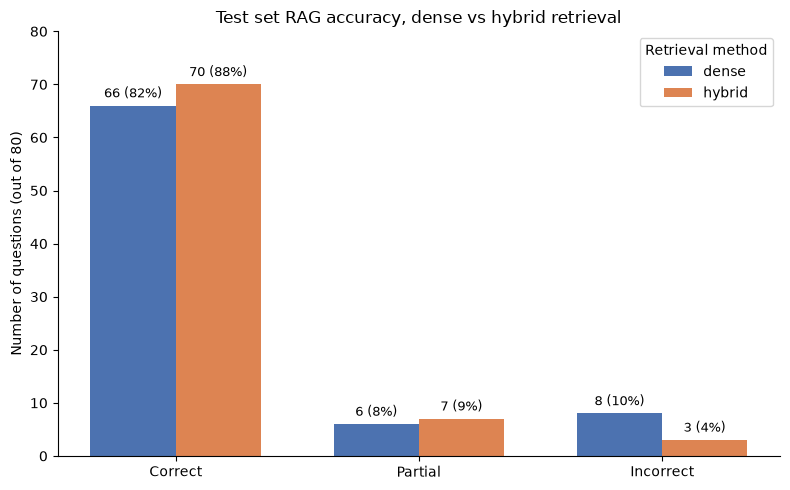

In [ ]:
results_data = {
    "dense":  {"correct": 66, "partial": 6, "incorrect": 8},
    "hybrid": {"correct": 70, "partial": 7, "incorrect": 3},
}

categories = ["correct", "partial", "incorrect"]
systems = list(results_data.keys())
system_colors = {"dense": "#4C72B0", "hybrid": "#DD8452"}

x = np.arange(len(categories))
width = 0.35

fig, ax = plt.subplots(figsize=(8, 5))
for i, system in enumerate(systems):
    counts = [results_data[system][cat] for cat in categories]
    total = sum(results_data[system].values())
    offset = (i - 0.5) * width
    bars = ax.bar(x + offset, counts, width, label=system, color=system_colors[system])
    for bar, count in zip(bars, counts):
        pct = 100 * count / total
        ax.text(bar.get_x() + bar.get_width() / 2, count + 1,
                f"{count} ({pct:.0f}%)", ha="center", va="bottom", fontsize=9)

ax.set_xticks(x)
ax.set_xticklabels([c.capitalize() for c in categories])
ax.set_ylabel("Number of questions (out of 80)")
ax.set_title("Test set RAG accuracy, dense vs hybrid retrieval")
ax.legend(title="Retrieval method")
ax.set_ylim(0, 80)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
fig.tight_layout()
plt.show()

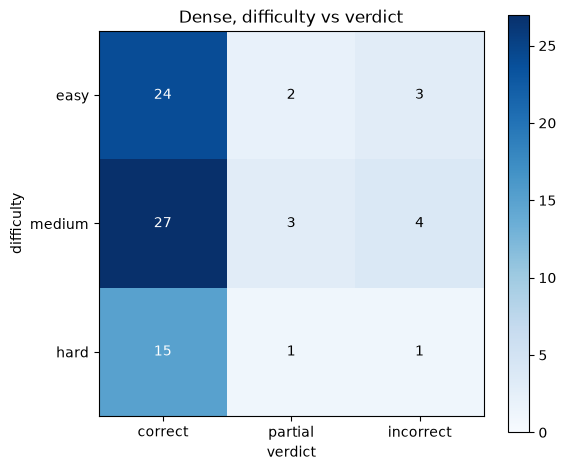

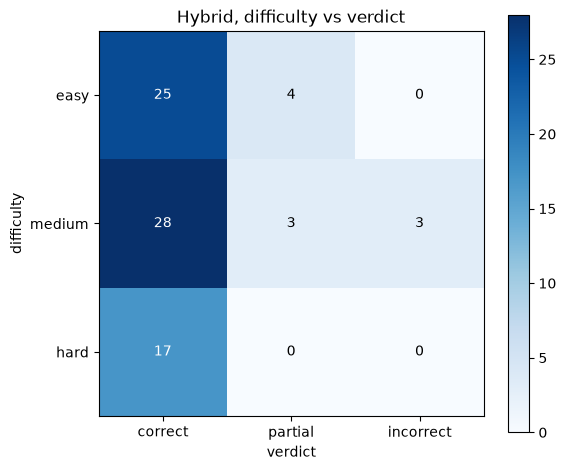

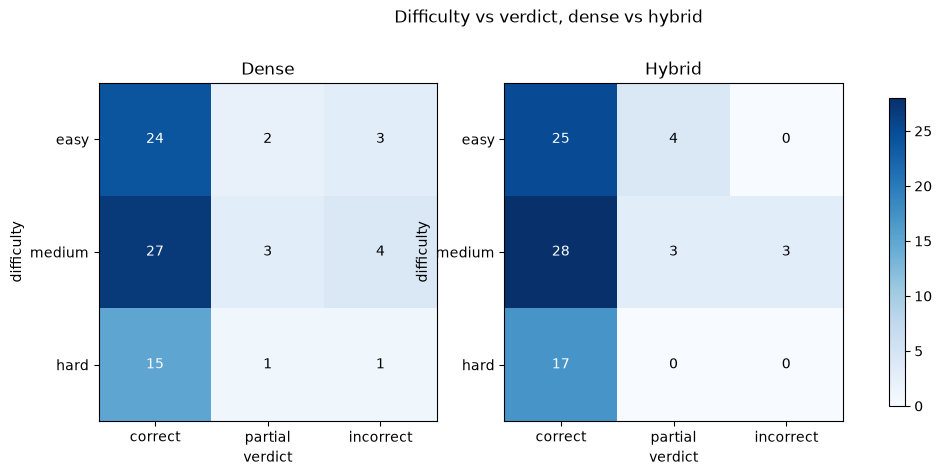

In [ ]:
dense_rows_test = dense_test_rows
hybrid_rows_test = hybrid_rows_test

def difficulty_verdict_heatmap(rows, title, ax, vmax):
    df = pd.DataFrame(rows)
    verdict_order = ["correct", "partial", "incorrect"]
    difficulty_order = ["easy", "medium", "hard"]
    crosstab = pd.crosstab(df["difficulty"], df["verdict"]).reindex(
        index=difficulty_order, columns=verdict_order, fill_value=0
    )
    im = ax.imshow(crosstab.values, cmap="Blues", vmin=0, vmax=vmax)
    ax.set_xticks(range(len(verdict_order)))
    ax.set_yticks(range(len(difficulty_order)))
    ax.set_xticklabels(verdict_order)
    ax.set_yticklabels(difficulty_order)
    ax.set_xlabel("verdict")
    ax.set_ylabel("difficulty")
    ax.set_title(title)
    threshold = vmax / 2
    for i in range(len(difficulty_order)):
        for j in range(len(verdict_order)):
            val = crosstab.values[i, j]
            color = "white" if val > threshold else "black"
            ax.text(j, i, str(val), ha="center", va="center", color=color)
    return im


# 1. dense alone
fig, ax = plt.subplots(figsize=(6, 5))
im = difficulty_verdict_heatmap(dense_rows_test, "Dense, difficulty vs verdict", ax, vmax=None or pd.crosstab(pd.DataFrame(dense_rows_test)["difficulty"], pd.DataFrame(dense_rows_test)["verdict"]).values.max())
fig.colorbar(im, ax=ax)
fig.tight_layout()
plt.show()

# 2. hybrid alone
fig, ax = plt.subplots(figsize=(6, 5))
im = difficulty_verdict_heatmap(hybrid_rows_test, "Hybrid, difficulty vs verdict", ax, vmax=pd.crosstab(pd.DataFrame(hybrid_rows_test)["difficulty"], pd.DataFrame(hybrid_rows_test)["verdict"]).values.max())
fig.colorbar(im, ax=ax)
fig.tight_layout()
plt.show()

# 3. side by side, shared color scale so intensity is directly comparable
shared_vmax = max(
    pd.crosstab(pd.DataFrame(dense_rows_test)["difficulty"], pd.DataFrame(dense_rows_test)["verdict"]).values.max(),
    pd.crosstab(pd.DataFrame(hybrid_rows_test)["difficulty"], pd.DataFrame(hybrid_rows_test)["verdict"]).values.max(),
)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
im1 = difficulty_verdict_heatmap(dense_rows_test, "Dense", axes[0], shared_vmax)
im2 = difficulty_verdict_heatmap(hybrid_rows_test, "Hybrid", axes[1], shared_vmax)
fig.colorbar(im1, ax=axes, shrink=0.8)
fig.suptitle("Difficulty vs verdict, dense vs hybrid")
plt.show()